

### Describtion of the problem:
#### Look at the images and consider how to distinguish between fat and meat.
In colour - meet is red, fat is white.
#### Which visual changes are apparant in the salami over the 28 days?
It gets darker around the edges and the white stripe around the corner shows up. Also, it seems that fat is more apparent, the "bulbs" are also larger (they appear in larger chunks). The surface seems more smooth. The edge is less circullar. I also think it could have gotten smaller? 
#### How can these changes be measured from the images?
* We could look into color distributions, color ratios. of red to white
* look for single big white chunks by applying circular filters?
* the same for black around the edges
* Apply some filters to find these non-smooth areas (very apparent in the beggining).  
* measure the area and ovalness of the salami
#### Load a multi spectral image in MATLAB or PYTHON and investigate the data.
BELOW

In [1]:
import helper_functions.helpFunctions as hf

dirIn = "./data/"

multiIm, annotationIm = hf.loadMulti(
    "multispectral_day20.mat", "annotation_day20.png", dirIn
)

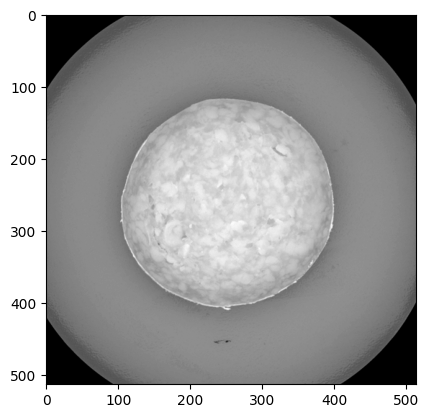

In [2]:
import matplotlib.pyplot as plt

plt.imshow(multiIm[:, :, 13], cmap="gray")

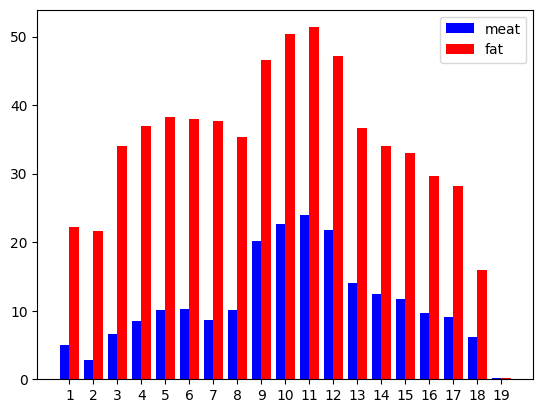

In [3]:
import numpy as np

fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])
meatPix, meatR, meatC = hf.getPix(multiIm, annotationIm[:, :, 2])

x = np.arange(1, 20)
width = 0.4
plt.figure()
plt.bar(x, np.var(meatPix, 0), width, color="b", label="meat")
offset = width
plt.bar(x + offset, np.var(fatPix, 0), width, color="r", label="fat")
plt.xticks(x + width / 2, x)
plt.legend()
plt.show()

So, that's after reading the section
### Formulation of the mathematical model:
#### Describe the mathematical model
The goal of the model is to classificy the pixel and meat and fat.

The model simply assumes that the samples are normally distributed with different means and standard deviations.
#### Why do we expect it to work?
* Assuming normal distrbituion: usually biological data is normally distributed.
* We assume the means should be different - from looking at the data
#### What are the limitations of the model?
* The assumption of the same standard deviation is simply wrong, given the plot.
* The assumption of the independence - It is false, because of the location dependence. This is not a noise, if a pixel is white, then likely its surrounding is white as well. I do not think it breaks down the model, but is a missed opportunity. However, it should hold across the bigger window.

### Analysis of the data



#### Investigate the data
* The histgram function is not normalized, so simply more pixels = higher; when comparing both of them.

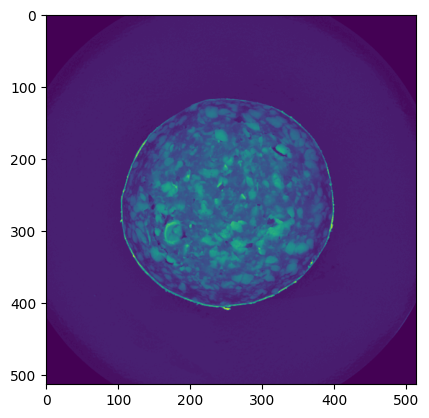

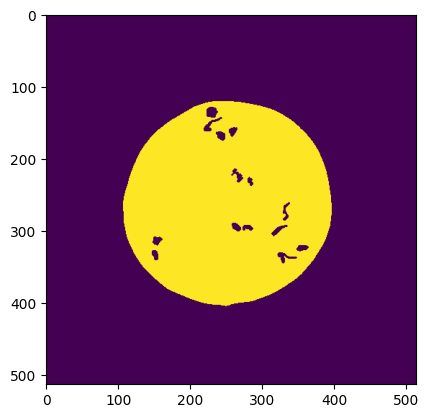

[[17 12 16 ... 48 44  2]
 [17 11 16 ... 47 43  2]
 [17 11 15 ... 47 44  2]
 ...
 [23 18 24 ... 53 48  1]
 [26 21 27 ... 53 49  1]
 [25 21 26 ... 54 48  1]]


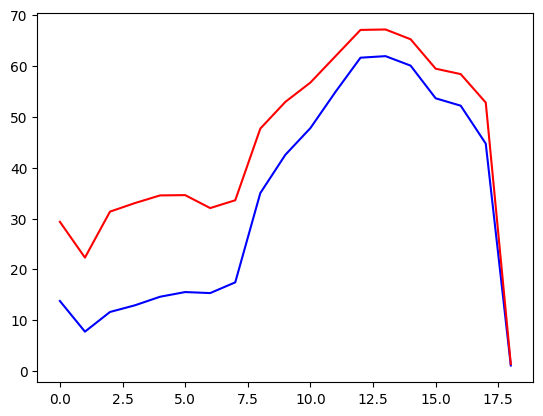

In [4]:
multiIm, annotationIm = hf.loadMulti(
    "multispectral_day20.mat", "annotation_day20.png", dirIn
)
# %%
# Show image of spectral band 7
plt.imshow(multiIm[:, :, 6])
plt.show()

# %%
# annotationIm is a binary image with 3 layers
annotationIm.shape

# %%
# In each layer we have a binary image:
# 0 - background with salami
# 1 fat annotation
# 2 meat annotation

# Here we show the meat annotation
plt.imshow(annotationIm[:, :, 0])
plt.show()

# %%
# The function getPix extracts the multi spectral pixels from the annotation
# Here is an example with meat- and fat annotation
fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])
meatPix, meatR, meatC = hf.getPix(multiIm, annotationIm[:, :, 2])

# %%
print(fatPix)
# %%
# Here we plot the mean values for pixels with meat and fat respectively
plt.plot(np.mean(meatPix, 0), "b")
plt.plot(np.mean(fatPix, 0), "r")
plt.show()


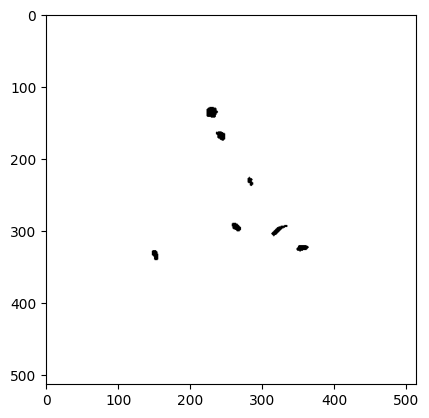

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [5]:
# %%
# The function setImagePix produces a colour image
# where the pixel coordinates are given as input
# Load RGB image
imRGB = plt.imread(dirIn + "color_day20.png")

# Pixel coordinates for the fat annotation
fatPix, fatR, fatC = hf.getPix(multiIm, annotationIm[:, :, 1])

# Concatenate the pixel coordinates to a matrix
pixId = np.stack((fatR, fatC), axis=1)

# Make the new images
rgbOut = hf.setImagePix(imRGB, pixId)
plt.imshow(rgbOut, cmap="gray")
plt.show()


# %%
rgbOut


#### Spectral distribution

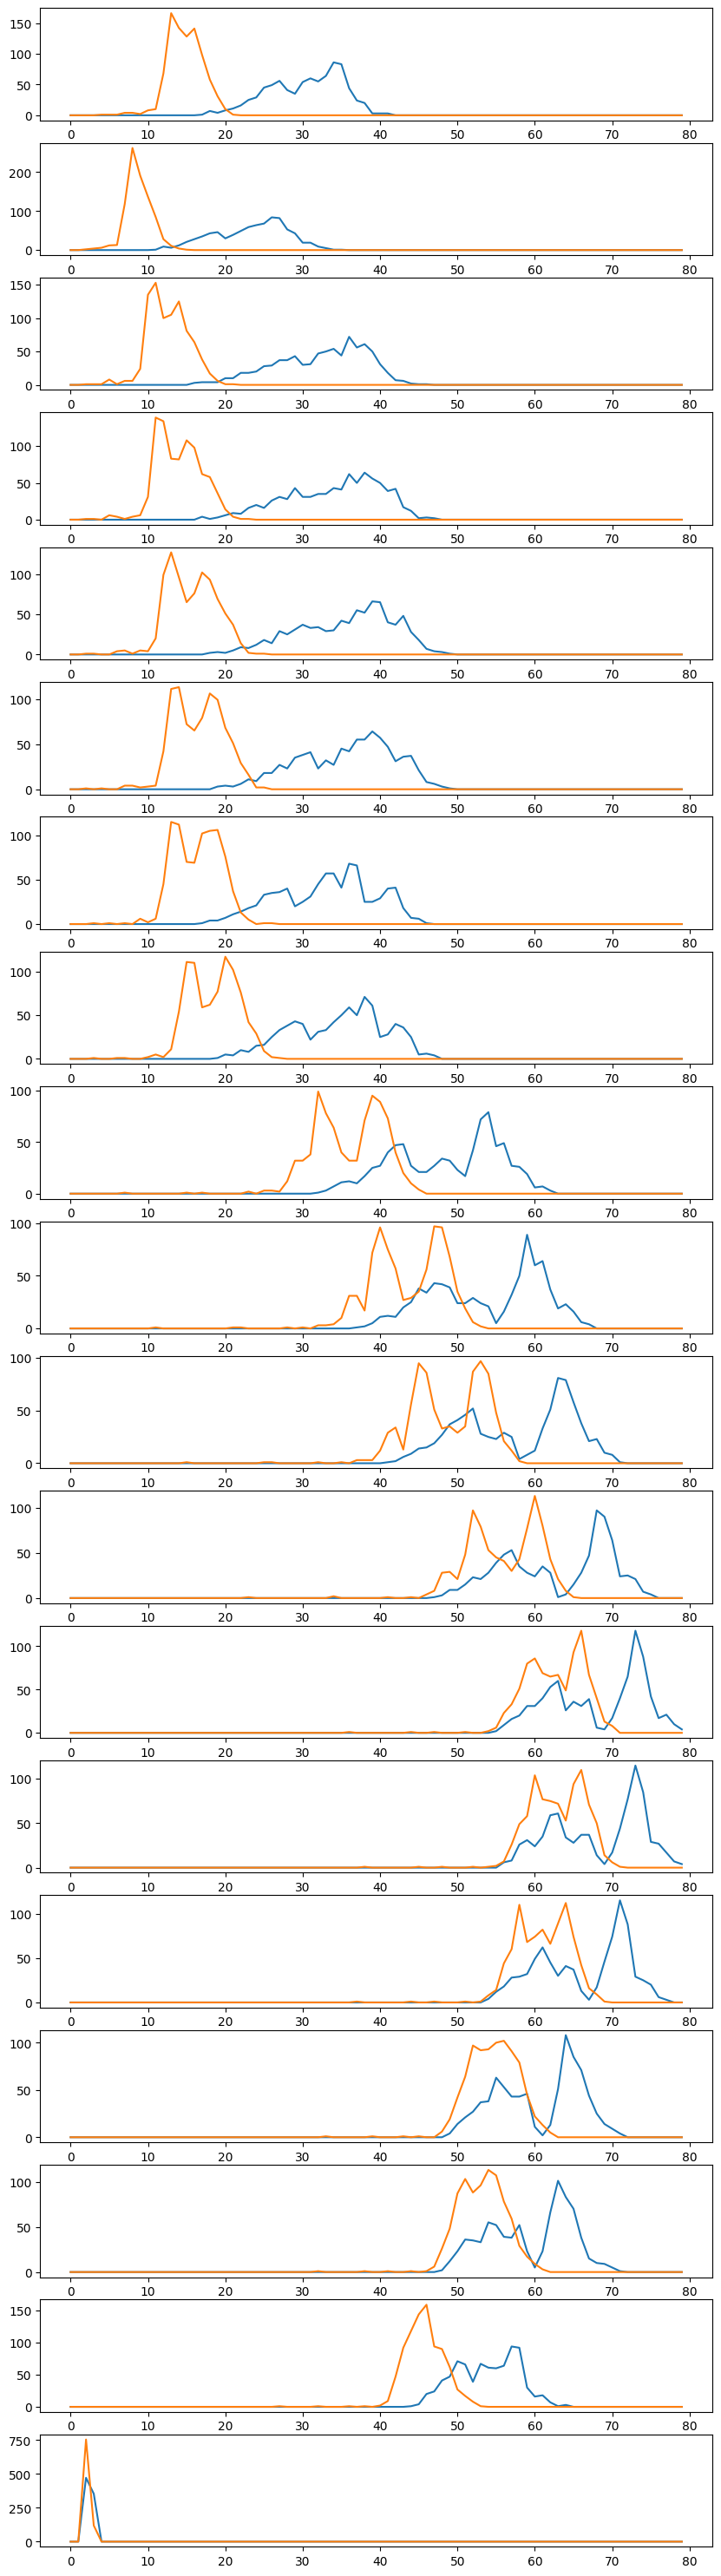

In [6]:
n_layers = 19
fig, ax = plt.subplots(n_layers, 1, figsize=(10, 2 * n_layers))
hist_pairs = []
for layer_id in range(0, n_layers):
    h = hf.showHistograms(
        multiIm, annotationIm[:, :, 1:3], layer_id, False, ["fat", "meat"]
    )
    hist_pairs.append(h)
    ax[layer_id].plot(h[0:80, :])
plt.show()


In [7]:
hist_pairs

[array([[  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   1.],
        [  0.,   1.],
        [  0.,   1.],
        [  0.,   4.],
        [  0.,   4.],
        [  0.,   2.],
        [  0.,   8.],
        [  0.,  10.],
        [  0.,  68.],
        [  0., 166.],
        [  0., 142.],
        [  0., 128.],
        [  0., 141.],
        [  1.,  98.],
        [  7.,  58.],
        [  4.,  31.],
        [  8.,  10.],
        [ 11.,   1.],
        [ 16.,   0.],
        [ 25.,   0.],
        [ 29.,   0.],
        [ 45.,   0.],
        [ 49.,   0.],
        [ 56.,   0.],
        [ 41.,   0.],
        [ 35.,   0.],
        [ 54.,   0.],
        [ 60.,   0.],
        [ 55.,   0.],
        [ 64.,   0.],
        [ 86.,   0.],
        [ 83.,   0.],
        [ 44.,   0.],
        [ 24.,   0.],
        [ 20.,   0.],
        [  3.,   0.],
        [  3.,   0.],
        [  3.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [ 

#### Is it a reasonable assumption that each pixel is either meat or fat?
I think mostly it is a reasonable assumption, though I am indeed seeing that sometimes, fat is 'seen' through a thin layer of meat atop.#


### Threshold value for a single spectral band

1. Calculate the threshold value t for all spectral bands for day 1.
2. Calculate the error rate for each spectral band.
3. Identify the spectral band, which has the best discriminative properties for meat and fat.
4. Classify the entire image of the salami for day 1, and visualise it.

#### Helper functions

In [8]:
rgbOut.shape

(514, 514, 3)

In [9]:
def LSD_discriminant(mu, var, prior):
    return lambda x: x * mu / var - mu**2 / (var * 2) + np.log(prior)


def LSD_classifier(mu1, var1, prior1, mu2, var2, prior2):
    disc1 = LSD_discriminant(mu1, var1, prior1)
    disc2 = LSD_discriminant(mu2, var2, prior2)
    return lambda x: 1 if disc1(x) > disc2(x) else 0


def class_hat_mean(x):
    return np.mean(x)


def pooled_hat_var(x, y):
    x_hat_var = np.var(x, axis=0)
    y_hat_var = np.var(y, axis=0)
    n_x = len(x)
    n_y = len(y)
    return ((n_x - 1) * x_hat_var + (n_y - 1) * y_hat_var) / (n_x + n_y - 2)


def prior(x):
    total = 514 * 514
    return x.shape[0] / total


### test for day one

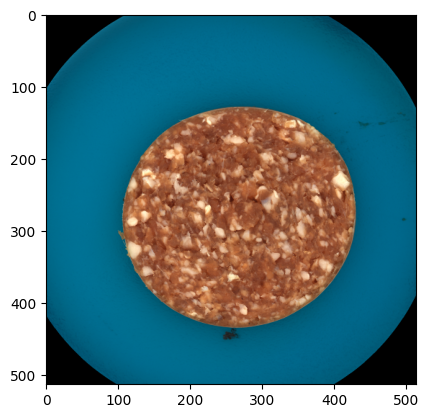

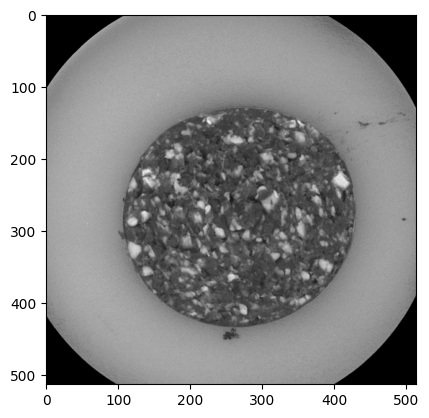

In [10]:
multiIm1, annotationIm1 = hf.loadMulti(
    "multispectral_day01.mat", "annotation_day01.png", dirIn
)
fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

plt.imshow(plt.imread("./data/color_day01.png"))
### for day one
fatPix1l1 = fatPix1[:, 0]
meatPix1l1 = meatPix1[:, 0]
layer_1 = multiIm1[:, :, 0]

fat_mean_1l1 = class_hat_mean(fatPix1l1)
meat_mean_1l1 = class_hat_mean(meatPix1l1)

fat_meat_pooled_var_1l1 = pooled_hat_var(meatPix1l1, fatPix1l1)

prior_fat_1l1 = prior(fatPix1l1)
prior_meat_1l1 = prior(meatPix1l1)

LSD_1l1 = LSD_classifier(
    fat_mean_1l1,
    fat_meat_pooled_var_1l1,
    prior_fat_1l1,
    meat_mean_1l1,
    fat_meat_pooled_var_1l1,
    prior_meat_1l1,
)

plt.figure()
plt.imshow(layer_1, cmap="gray")
plt.show()


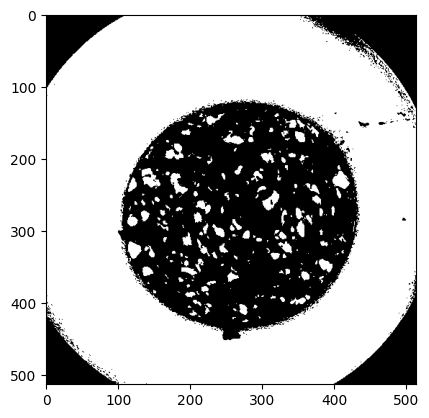

In [11]:
labeled_layer_1 = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(layer_1.shape[0]):
    for j in range(layer_1.shape[1]):
        labeled_layer_1[i, j] = LSD_1l1(layer_1[i, j])
plt.figure()
plt.imshow(labeled_layer_1, cmap="gray")
plt.show()

In [12]:
labeled_layer_1[*[2, 3]]

np.float64(0.0)

#### All steps in one go

In [13]:
### Calculate the accuracy of the classifier for layer 1 on the known pixels
fatPixId1 = np.stack((fatR1, fatC1), axis=1)
meatPixId1 = np.stack((meatR1, meatC1), axis=1)


def error_rate(labeled_image, fatPixId, meatPixId):

    correct = 0
    total = fatPixId.shape[0] + meatPixId.shape[0]
    for pix in fatPixId:
        pred_val = labeled_image[*pix]
        correct += pred_val == 1
    for pix in meatPixId:
        pred_val = labeled_image[*pix]
        correct += pred_val == 0
    # print("accuracy:", correct / total)
    # print("error rate:", 1 - correct / total)
    return 1 - correct / total


error_rate(labeled_layer_1, fatPixId1, meatPixId1)

np.float64(0.01043478260869568)

In [26]:
error_rates = []
for layer_id in range(n_layers):
    ### for day one
    fatPix1l = fatPix1[:, layer_id]
    meatPix1l = meatPix1[:, layer_id]
    layer = multiIm1[:, :, layer_id]

    fat_mean_1l = class_hat_mean(fatPix1l)
    meat_mean_1l = class_hat_mean(meatPix1l)

    fat_var_1l = pooled_hat_var(fatPix1l, meatPix1l)
    meat_var_1l = pooled_hat_var(meatPix1l, fatPix1l)

    prior_fat_1l = prior(fatPix1l)
    prior_meat_1l = prior(meatPix1l)

    LSD_1l = LSD_classifier(
        fat_mean_1l,
        fat_var_1l,
        prior_fat_1l,
        meat_mean_1l,
        meat_var_1l,
        prior_meat_1l,
    )
    labeled_layer = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

    for i in range(layer.shape[0]):
        for j in range(layer.shape[1]):
            labeled_layer[i, j] = LSD_1l(layer[i, j])
    # plt.figure()
    # plt.imshow(labeled_layer, cmap="gray")
    # plt.show()

    error_rates.append(error_rate(labeled_layer, fatPixId1, meatPixId1))

#### Identify the spectral band, which has the best discriminative properties for meat and fat.

In [29]:
error_rates

[np.float64(0.01043478260869568),
 np.float64(0.016231884057971047),
 np.float64(0.012173913043478257),
 np.float64(0.008695652173912993),
 np.float64(0.008115942028985468),
 np.float64(0.01043478260869568),
 np.float64(0.01043478260869568),
 np.float64(0.01043478260869568),
 np.float64(0.012173913043478257),
 np.float64(0.01043478260869568),
 np.float64(0.012173913043478257),
 np.float64(0.00521739130434784),
 np.float64(0.011014492753623206),
 np.float64(0.00927536231884063),
 np.float64(0.004637681159420315),
 np.float64(0.00927536231884063),
 np.float64(0.015072463768115996),
 np.float64(0.01565217391304352),
 np.float64(0.43826086956521737)]

In [27]:
print(np.min(error_rates))
print(np.argmin(error_rates))
best_layer_id = np.argmin(error_rates)

0.004637681159420315
14


#### Classify the entire image of the salami for day 1, and visualise it.

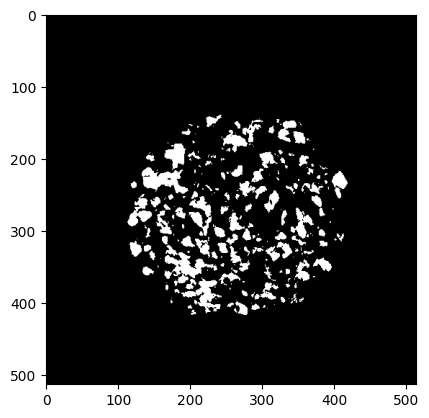

np.float64(0.004637681159420315)

In [30]:
### for day one
fatPix1l = fatPix1[:, best_layer_id]
meatPix1l = meatPix1[:, best_layer_id]
layer = multiIm1[:, :, best_layer_id]

fat_mean_1l = class_hat_mean(fatPix1l)
meat_mean_1l = class_hat_mean(meatPix1l)

fat_meat_pooled_var_1l = pooled_hat_var(fatPix1l, meatPix1l)

prior_fat_1l = prior(fatPix1l)
prior_meat_1l = prior(meatPix1l)

LSD_1l_best = LSD_classifier(
    fat_mean_1l,
    fat_meat_pooled_var_1l,
    prior_fat_1l,
    meat_mean_1l,
    fat_meat_pooled_var_1l,
    prior_meat_1l,
)
labeled_layer = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(layer.shape[0]):
    for j in range(layer.shape[1]):
        labeled_layer[i, j] = LSD_1l_best(layer[i, j])
plt.figure()
plt.imshow(labeled_layer, cmap="gray")
plt.show()

error_rate(labeled_layer, fatPixId1, meatPixId1)


### Threshold value for a single spectral band
1. Calculate the threshold value t for all spectral bands for day 1.
2. Calculate the error rate for each spectral band.
3. Identify the spectral band, which has the best discriminative properties for meat and fat.
4. Classify the entire image of the salami for day 1, and visualise it.

In [18]:
def class_md_hat_mean(X):
    """Assumes observations in X are in rows, and dimensions in columns"""
    return np.mean(X, axis=0)


def class_hat_covar(X, X_hat_mean=None):
    """Observations are in row. Computes covariance matrix"""
    if X_hat_mean is None:
        X_hat_mean = class_md_hat_mean(X)
    X_c = X - X_hat_mean
    n = X.shape[0]
    return 1 / (n - 1) * X_c.T @ X_c


def pool_hat_covar(X, Y):
    """Observations are in row. Computes pooled covariance matrix"""
    X_hat_covar = class_hat_covar(X)
    Y_hat_covar = class_hat_covar(Y)
    n_X = X.shape[0]
    n_Y = Y.shape[0]
    return ((n_X - 1) * X_hat_covar + (n_Y - 1) * Y_hat_covar) / (n_X + n_Y - 2)


def prior(x):
    total = 514 * 514
    return x.shape[0] / total


### test for day one


def md_LSD_discriminant(X_hat_mean, X_pool_covar, prior):
    """Multi dimensional, observation provided as a row"""
    inv_covar = np.linalg.inv(X_pool_covar)
    return lambda x: (
        x @ inv_covar @ X_hat_mean.T
        - 1 / 2 * X_hat_mean @ inv_covar @ X_hat_mean.T
        + np.log(prior)
    )


def md_LSD_classifier(X_hat_mean_1, X_hat_mean_2, prior_1, prior_2, X_pool_hat_covar):
    disc1 = md_LSD_discriminant(X_hat_mean_1, X_pool_hat_covar, prior_1)
    disc2 = md_LSD_discriminant(X_hat_mean_2, X_pool_hat_covar, prior_2)
    # print(disc1(x), disc2(x))
    return lambda x: 1 if disc1(x) > disc2(x) else 0


In [19]:
import helper_functions.helpFunctions as hf
import matplotlib.pyplot as plt
import numpy as np

dirIn = "./data/"


In [20]:
fatPix.shape

(826, 19)

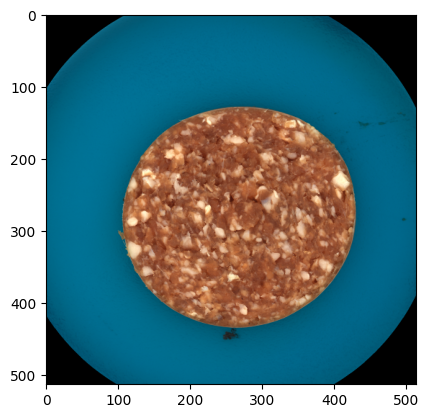

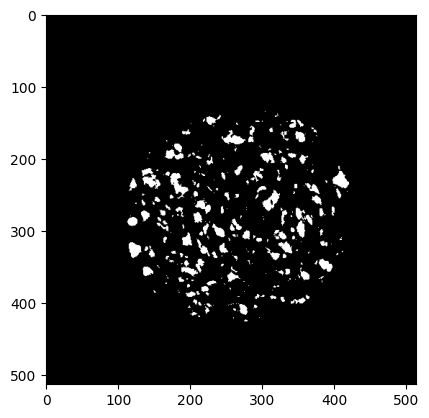

np.float64(0.005797101449275366)

In [21]:
# multivariate case


multiIm1, annotationIm1 = hf.loadMulti(
    "multispectral_day01.mat", "annotation_day01.png", dirIn
)
fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

plt.imshow(plt.imread("./data/color_day01.png"))
### for day one

fat_mean_1 = class_md_hat_mean(fatPix1)
meat_mean_1 = class_md_hat_mean(meatPix1)

fat_mean_pooled_covar = pool_hat_covar(fatPix1, meatPix1)


prior_fat_1 = prior(fatPix1)
prior_meat_1 = prior(meatPix1)

LSD_1 = md_LSD_classifier(
    fat_mean_1,
    meat_mean_1,
    prior_fat_1,
    prior_meat_1,
    fat_mean_pooled_covar,
)

labeled_multiIm1 = np.zeros((multiIm1.shape[0], multiIm1.shape[1]))

for i in range(multiIm1.shape[0]):
    for j in range(multiIm1.shape[1]):
        labeled_multiIm1[i, j] = LSD_1(multiIm1[i, j])
plt.figure()
plt.imshow(labeled_multiIm1, cmap="gray")
plt.show()

error_rate(labeled_multiIm1, fatPixId1, meatPixId1)

In [22]:
error_rate(labeled_multiIm1, fatPixId1, meatPixId1)

np.float64(0.005797101449275366)

In [23]:
fatR1

array([173, 173, 173, 173, 173, 173, 174, 174, 174, 174, 174, 174, 174,
       174, 174, 174, 174, 175, 175, 175, 175, 175, 175, 175, 175, 175,
       175, 175, 175, 175, 176, 176, 176, 176, 176, 176, 176, 176, 176,
       176, 176, 176, 176, 176, 177, 177, 177, 177, 177, 177, 177, 177,
       177, 177, 177, 177, 177, 178, 178, 178, 178, 178, 178, 178, 178,
       178, 178, 178, 178, 179, 179, 179, 179, 179, 179, 179, 179, 179,
       179, 223, 223, 224, 224, 224, 224, 225, 225, 225, 225, 225, 225,
       226, 226, 226, 226, 226, 226, 226, 227, 227, 227, 227, 227, 227,
       227, 227, 227, 228, 228, 228, 228, 228, 228, 228, 228, 228, 228,
       228, 228, 228, 229, 229, 229, 229, 229, 229, 229, 229, 229, 229,
       229, 229, 229, 229, 230, 230, 230, 230, 230, 230, 230, 230, 230,
       230, 230, 230, 230, 230, 231, 231, 231, 231, 231, 231, 231, 231,
       231, 231, 231, 231, 231, 231, 231, 232, 232, 232, 232, 232, 232,
       232, 232, 232, 232, 232, 232, 232, 232, 232, 232, 232, 23

# Calculation For All Days
1. Classify fat and meat for the remaining days with the models trained on day 1.
2. Calculate the error rate for the annotated areas for the remaining days. How is the performance of
the two models?
3. Classify again the entire images for the remaining days and, and visualise them. Judged on the
visualisations, which model performs best?

Day 01 - One Dimensional LSD Accuracy: 0.9953623188405797 - Error Rate: 0.004637681159420315
Day 01 - Multi Dimensional LSD Accuracy: 0.9942028985507246 - Error Rate: 0.005797101449275366


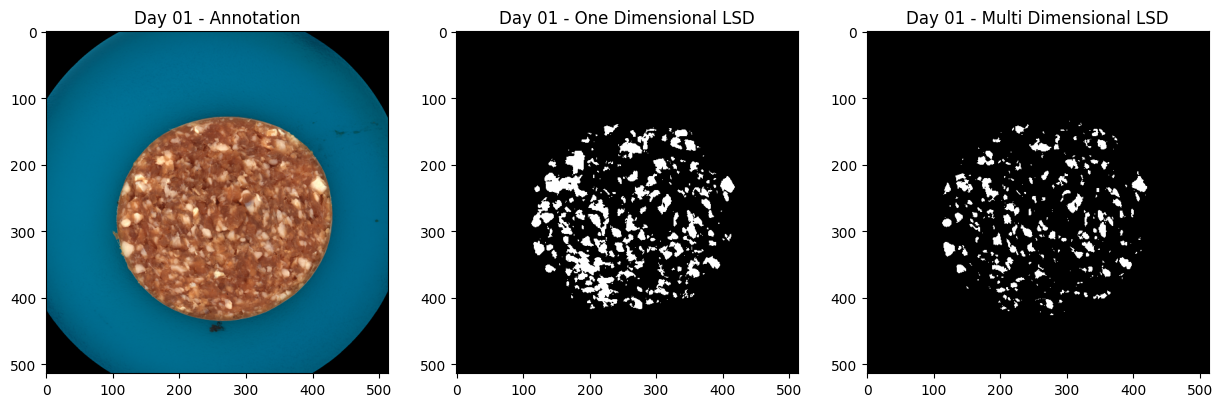

Day 06 - One Dimensional LSD Accuracy: 0.8917228103946102 - Error Rate: 0.10827718960538979
Day 06 - Multi Dimensional LSD Accuracy: 0.9783445620789221 - Error Rate: 0.021655437921077936


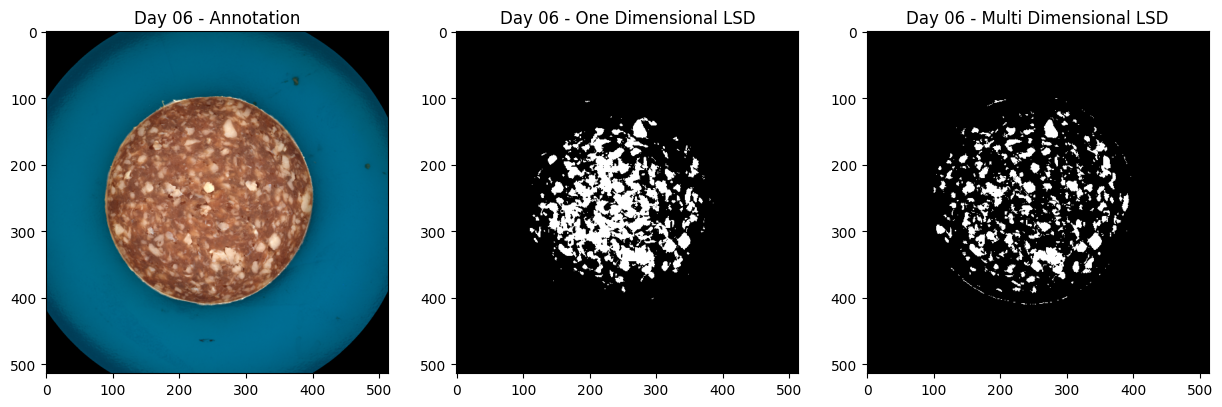

Day 13 - One Dimensional LSD Accuracy: 0.8810810810810811 - Error Rate: 0.11891891891891893
Day 13 - Multi Dimensional LSD Accuracy: 0.9129129129129129 - Error Rate: 0.08708708708708712


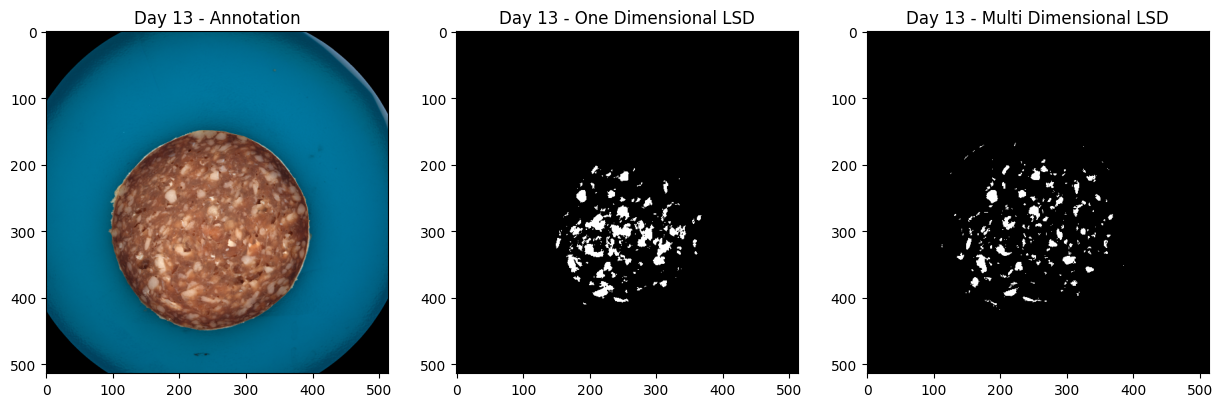

Day 20 - One Dimensional LSD Accuracy: 0.7570588235294118 - Error Rate: 0.24294117647058822
Day 20 - Multi Dimensional LSD Accuracy: 0.8605882352941177 - Error Rate: 0.13941176470588235


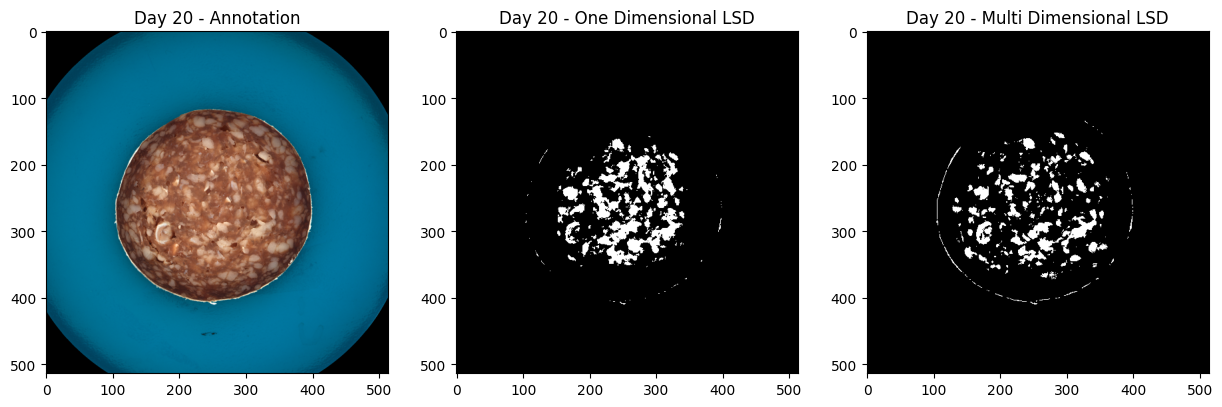

Day 28 - One Dimensional LSD Accuracy: 0.8151544401544402 - Error Rate: 0.18484555984555984
Day 28 - Multi Dimensional LSD Accuracy: 0.9391891891891891 - Error Rate: 0.060810810810810856


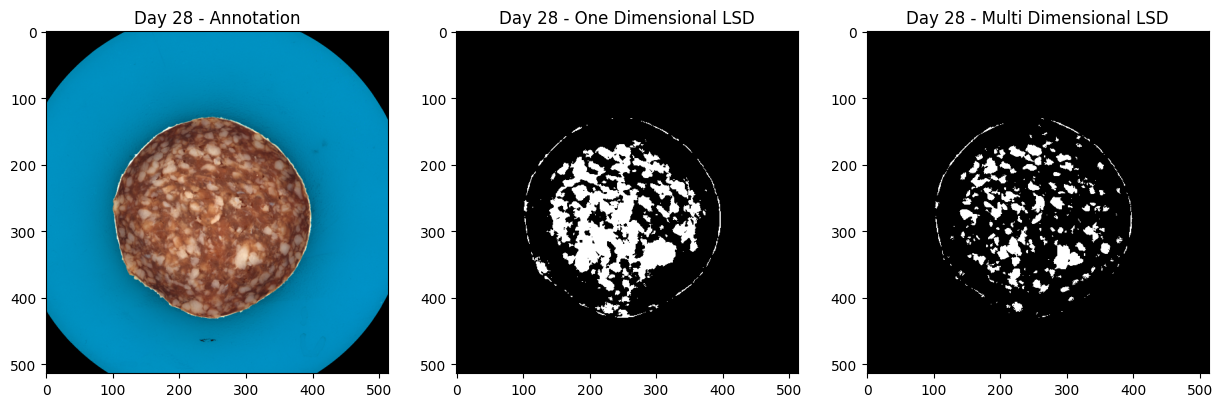

In [34]:
### Code Plan

### Load data
from tornado.gen import multi

test_days = ["01", "06", "13", "20", "28"]
test_days_data = {}
for day in test_days:
    multiIm, annotationIm = hf.loadMulti(
        f"multispectral_day{day}.mat", f"annotation_day{day}.png", dirIn
    )
    fat_annots = hf.getPix(multiIm, annotationIm[:, :, 1])
    meat_annots = hf.getPix(multiIm, annotationIm[:, :, 2])
    test_days_data[day] = {
        "multiIm": multiIm,
        "annotationIm": annotationIm,
        "fat_annots": fat_annots,
        "meat_annots": meat_annots,
    }
# fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
# meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])


### Iterate over the data
for day, data in test_days_data.items():
    multiIm = data["multiIm"]
    fatPix, fatR, fatC = data["fat_annots"]
    meatPix, meatR, meatC = data["meat_annots"]
    #### Create empty layers
    labeled_layer_one_dim = np.zeros((multiIm.shape[0], multiIm.shape[1]))
    labeled_layer_multi_dim = labeled_layer_one_dim.copy()
    #### laber the layer using both classifiers (define above) - LSD_1 and LSD_1l
    best_layer = multiIm[:, :, best_layer_id]
    for i in range(best_layer.shape[0]):
        for j in range(best_layer.shape[1]):
            labeled_layer_one_dim[i, j] = LSD_1l_best(best_layer[i, j])

    for i in range(multiIm.shape[0]):
        for j in range(multiIm.shape[1]):
            labeled_layer_multi_dim[i, j] = LSD_1(multiIm[i, j])
    #### Compute the error rates for both
    fatPixId = np.stack((fatR, fatC), axis=1)
    meatPixId = np.stack((meatR, meatC), axis=1)
    er_om = error_rate(labeled_layer_one_dim, fatPixId, meatPixId)
    print(
        f"Day {day} - One Dimensional LSD Accuracy: {1 - er_om} - Error Rate: {er_om}"
    )
    er_md = error_rate(labeled_layer_multi_dim, fatPixId, meatPixId)
    print(
        f"Day {day} - Multi Dimensional LSD Accuracy: {1 - er_md} - Error Rate: {er_md}"
    )
    #### Display the annotation and the annotations from two classifiers, in one row - print days.
    color_im = plt.imread(f"./data/color_day{day}.png")
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(color_im)
    ax[0].set_title(f"Day {day} - Annotation")
    ax[1].imshow(labeled_layer_one_dim, cmap="gray")
    ax[1].set_title(f"Day {day} - One Dimensional LSD")
    ax[2].imshow(labeled_layer_multi_dim, cmap="gray")
    ax[2].set_title(f"Day {day} - Multi Dimensional LSD")
    plt.show()

In [ ]:
### Multi looks better!

Training on each day and error calculated on all the other days:
1. Judging from the images, which day would you choose to train on and why??
2. Train the linear discriminant function on day 1, day 6 and so on, and for each day calculate the
error rate on all the other days.
3. Show the error rate for all days (5 training days x 4 test days = 20 error rates) in an appropriate
plot or table.
4. Why do we exclude the day we have trained on from the comparison?
5. Which day is the best to train the model on, and why?
6. What are the error sources in the model? Can we trust that the calculated fat and meat content in
the salami is the same as the real content?

1. I think the day 13. We want to have the image that is the most representative of them all. Day 13 if the first day that contains clearly seen shadow, while it is also not too strong. I think it might be a good trade-off thus.
4. It does not make a sense to do it at all, simply to test and train on main

In [35]:
### Load data for all days (again, yes)


days = ["01", "06", "13", "20", "28"]
days_data = {}
for day in days:
    multiIm, annotationIm = hf.loadMulti(
        f"multispectral_day{day}.mat", f"annotation_day{day}.png", dirIn
    )
    fat_annots = hf.getPix(multiIm, annotationIm[:, :, 1])
    meat_annots = hf.getPix(multiIm, annotationIm[:, :, 2])
    days_data[day] = {
        "multiIm": multiIm,
        "annotationIm": annotationIm,
        "fat_annots": fat_annots,
        "meat_annots": meat_annots,
    }
# fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
# meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

### Create results table
error_rates_table = np.zeros((len(days), len(days)))

### For each day,
#### train the multivariate LSD on it
for day, data in days_data.items():
    multiIm = data["multiIm"]
    fatPix, fatR, fatC = data["fat_annots"]
    meatPix, meatR, meatC = data["meat_annots"]

    fat_mean = class_md_hat_mean(fatPix)
    meat_mean = class_md_hat_mean(meatPix)

    fat_mean_pooled_covar = pool_hat_covar(fatPix, meatPix)

    prior_fat = prior(fatPix)
    prior_meat = prior(meatPix)

    LSD_classifier_day = md_LSD_classifier(
        fat_mean,
        meat_mean,
        prior_fat,
        prior_meat,
        fat_mean_pooled_covar,
    )
    #### obtain error rate having evaluated on the remaining days
    for eval_day, eval_data in days_data.items():
        if eval_day == day:
            continue
        eval_multiIm = eval_data["multiIm"]
        eval_fatPix, eval_fatR, eval_fatC = eval_data["fat_annots"]
        eval_meatPix, eval_meatR, eval_meatC = eval_data["meat_annots"]

        labeled_eval_multiIm = np.zeros((eval_multiIm.shape[0], eval_multiIm.shape[1]))

        for i in range(eval_multiIm.shape[0]):
            for j in range(eval_multiIm.shape[1]):
                labeled_eval_multiIm[i, j] = LSD_classifier_day(eval_multiIm[i, j])

        eval_fatPixId = np.stack((eval_fatR, eval_fatC), axis=1)
        eval_meatPixId = np.stack((eval_meatR, eval_meatC), axis=1)

        er_eval_md = error_rate(labeled_eval_multiIm, eval_fatPixId, eval_meatPixId)

        error_rates_table[days.index(day), days.index(eval_day)] = er_eval_md

        print(
            f"Trained on Day {day} - Evaluated on Day {eval_day} - Multi Dimensional LSD Accuracy: {1 - er_eval_md} - Error Rate: {er_eval_md}"
        )
#### Put that all into a table TxT

Trained on Day 01 - Evaluated on Day 06 - Multi Dimensional LSD Accuracy: 0.9783445620789221 - Error Rate: 0.021655437921077936
Trained on Day 01 - Evaluated on Day 13 - Multi Dimensional LSD Accuracy: 0.9129129129129129 - Error Rate: 0.08708708708708712
Trained on Day 01 - Evaluated on Day 20 - Multi Dimensional LSD Accuracy: 0.8605882352941177 - Error Rate: 0.13941176470588235
Trained on Day 01 - Evaluated on Day 28 - Multi Dimensional LSD Accuracy: 0.9391891891891891 - Error Rate: 0.060810810810810856
Trained on Day 06 - Evaluated on Day 01 - Multi Dimensional LSD Accuracy: 0.9756521739130435 - Error Rate: 0.024347826086956514
Trained on Day 06 - Evaluated on Day 13 - Multi Dimensional LSD Accuracy: 0.9843843843843844 - Error Rate: 0.015615615615615641
Trained on Day 06 - Evaluated on Day 20 - Multi Dimensional LSD Accuracy: 0.9564705882352941 - Error Rate: 0.04352941176470593
Trained on Day 06 - Evaluated on Day 28 - Multi Dimensional LSD Accuracy: 0.957046332046332 - Error Rate: 0

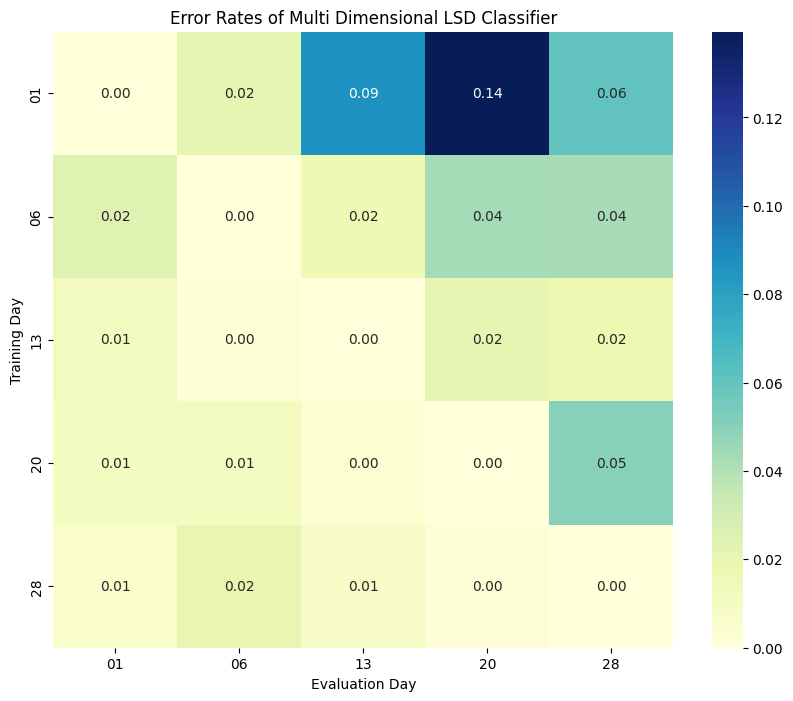

In [38]:
### Display the table as a heatmap, with days on x and y axis, and error rates in the cells
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(
    error_rates_table,
    xticklabels=days,
    yticklabels=days,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
)
plt.title("Error Rates of Multi Dimensional LSD Classifier")
plt.xlabel("Evaluation Day")
plt.ylabel("Training Day")
plt.show()

5. I think it is the dain 13. It achieves similar performance to the day 28. I would not pick the day 28, because it is the last day - it might be overfitted too much to older salamis and this is just a luck it was better than 13. (if we are doing this without a statistical test)

<Figure size 640x480 with 0 Axes>

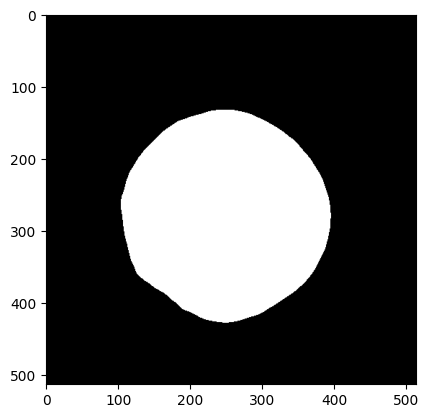

<Figure size 640x480 with 0 Axes>

In [52]:
plt.figure()
plt.imshow(annotationIm.max(axis=2), cmap="gray")
plt.figure()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.039215688..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.039215688..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.105882354..255.0].


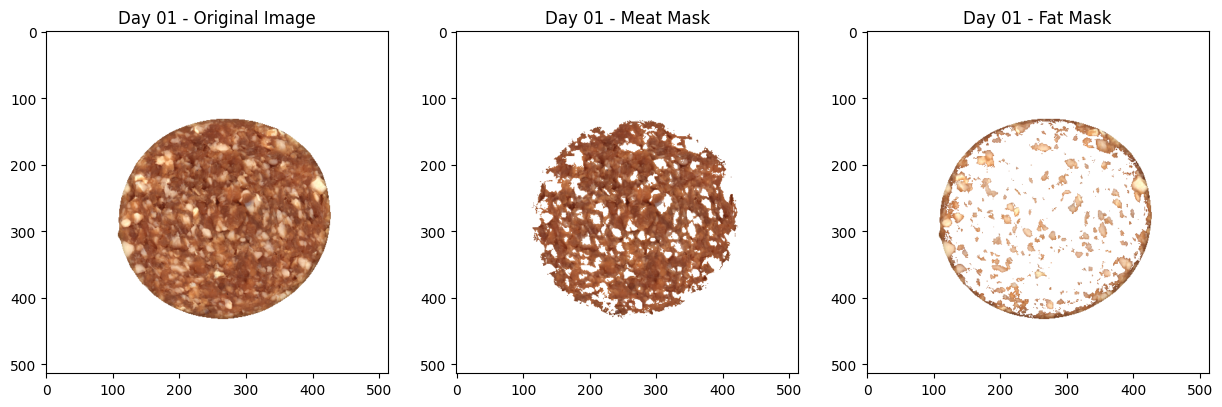

Day 01 - Fat Percentage: 25.78%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05490196..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05490196..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.105882354..255.0].


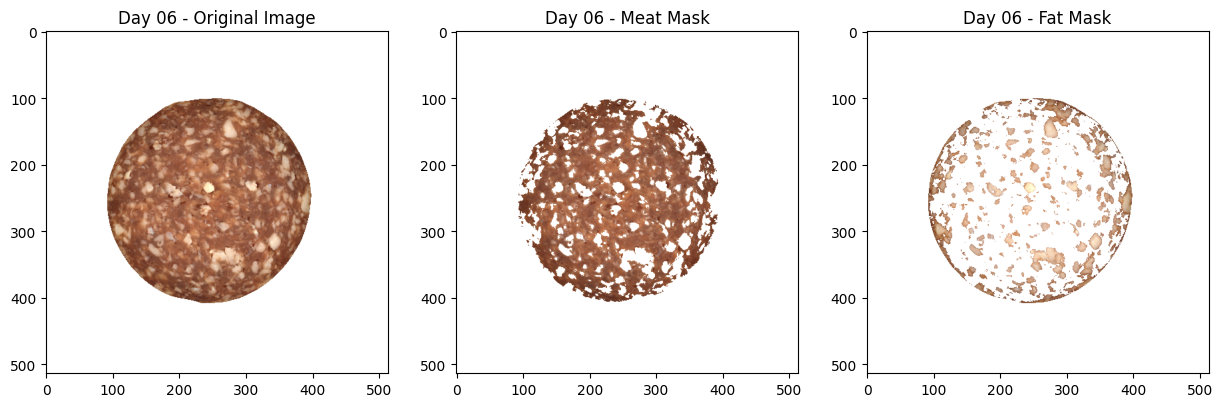

Day 06 - Fat Percentage: 26.48%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.023529412..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.023529412..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.15294118..255.0].


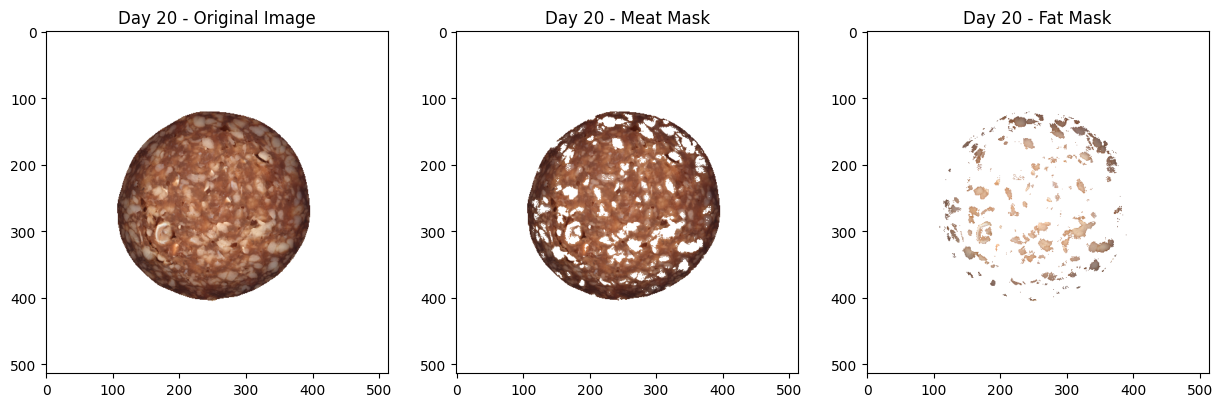

Day 20 - Fat Percentage: 15.29%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.07450981..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.07450981..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1764706..255.0].


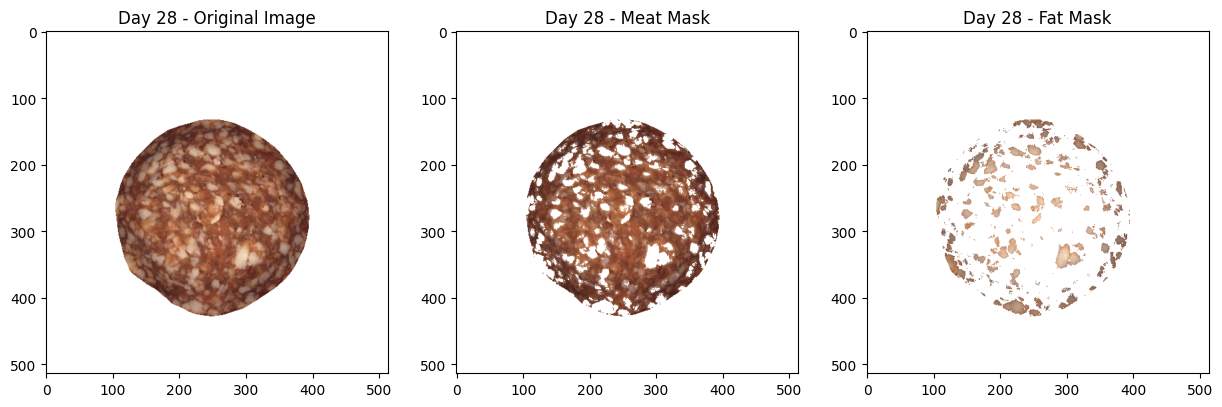

Day 28 - Fat Percentage: 19.53%


In [88]:
from helper_functions.helpFunctions import setImagePix
### Load data for all days (again, yes)

best_train_day = "13"


days = ["01", "06", "13", "20", "28"]
days_data = {}
for day in days:
    multiIm, annotationIm = hf.loadMulti(
        f"multispectral_day{day}.mat", f"annotation_day{day}.png", dirIn
    )
    fat_annots = hf.getPix(multiIm, annotationIm[:, :, 1])
    meat_annots = hf.getPix(multiIm, annotationIm[:, :, 2])
    days_data[day] = {
        "multiIm": multiIm,
        "annotationIm": annotationIm,
        "fat_annots": fat_annots,
        "meat_annots": meat_annots,
        "color_im": plt.imread(f"./data/color_day{day}.png"),
    }
# fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
# meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

### Create results table
# error_rates_table = np.zeros((len(days), len(days)))

data = days_data[best_train_day]

multiIm = data["multiIm"]
fatPix, fatR, fatC = data["fat_annots"]
meatPix, meatR, meatC = data["meat_annots"]

fat_mean = class_md_hat_mean(fatPix)
meat_mean = class_md_hat_mean(meatPix)

fat_mean_pooled_covar = pool_hat_covar(fatPix, meatPix)

prior_fat = prior(fatPix)
prior_meat = prior(meatPix)

LSD_classifier_day = md_LSD_classifier(
    fat_mean,
    meat_mean,
    prior_fat,
    prior_meat,
    fat_mean_pooled_covar,
)
#### obtain error rate having evaluated on the remaining days
for day, data in days_data.items():
    if day == best_train_day:
        continue

    multiIm = data["multiIm"]
    fatPix, fatR, fatC = data["fat_annots"]
    meatPix, meatR, meatC = data["meat_annots"]
    salami_region = data["annotationIm"].max(axis=2).astype(bool)

    labeled_multiIm = np.zeros((multiIm.shape[0], multiIm.shape[1]))

    labeled_x, labeled_y = np.where(salami_region)

    for i, j in zip(labeled_x, labeled_y):
        labeled_multiIm[i, j] = (
            LSD_classifier_day(multiIm[i, j]) + 1
        )  # add one to differentiate from background

    fatPixId = np.stack((fatR, fatC), axis=1)
    meatPixId = np.stack((meatR, meatC), axis=1)

    er_md = error_rate(labeled_multiIm, fatPixId, meatPixId)

    masked_colour_image = setImagePix(data["color_im"], salami_region)

    ### meat mask
    meatOut = hf.setImagePix(data["color_im"], labeled_multiIm == 1)

    fatOut = hf.setImagePix(data["color_im"], labeled_multiIm == 2)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(masked_colour_image)
    plt.title(f"Day {day} - Original Image")
    plt.subplot(1, 3, 2)
    plt.imshow(meatOut)
    plt.title(f"Day {day} - Meat Mask")
    plt.subplot(1, 3, 3)
    plt.imshow(fatOut)
    plt.title(f"Day {day} - Fat Mask")
    plt.show()

    # print fat percentage
    fat_percentage = np.sum(labeled_multiIm == 2) / np.sum(salami_region)
    print(f"Day {day} - Fat Percentage: {fat_percentage:.2%}")

#### Put that all into a table TxT

In [ ]:
### Unfortunately we are seeing that

6. Clearly, for the first 3 days it seems to be doing good, however, day 28 and day 20 seems not doing that great (especially fat seems not to be taken into accounnt appropriately)

30% fat in batch of salamis - OK.
Prior knowledge:
1. Incorporate this information into your linear discriminant model
2. Does it change your estimates?

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.039215688..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.039215688..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.105882354..255.0].


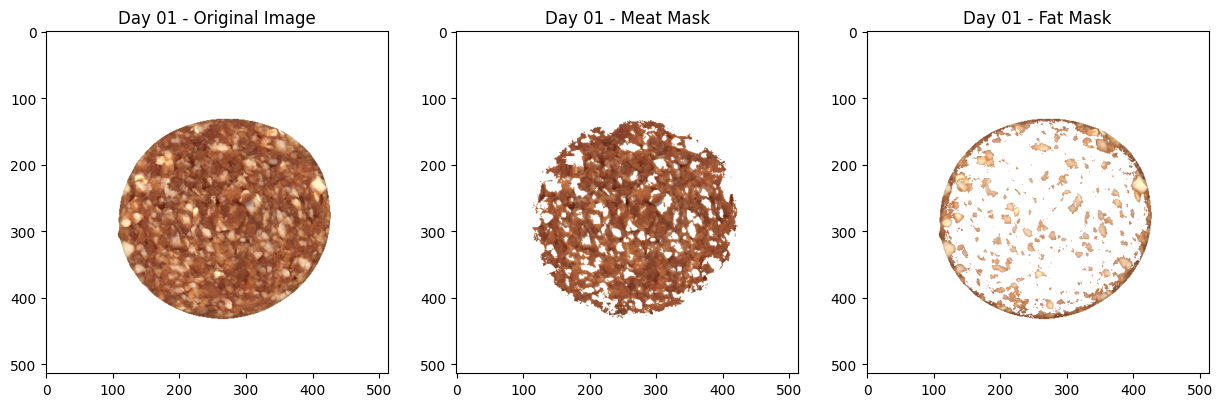

Day 01 - Fat Percentage: 25.38%
Day 01 - Multi Dimensional LSD Accuracy: 0.008115942028985468 - Error Rate: 0.9918840579710145


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05490196..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.05490196..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.105882354..255.0].


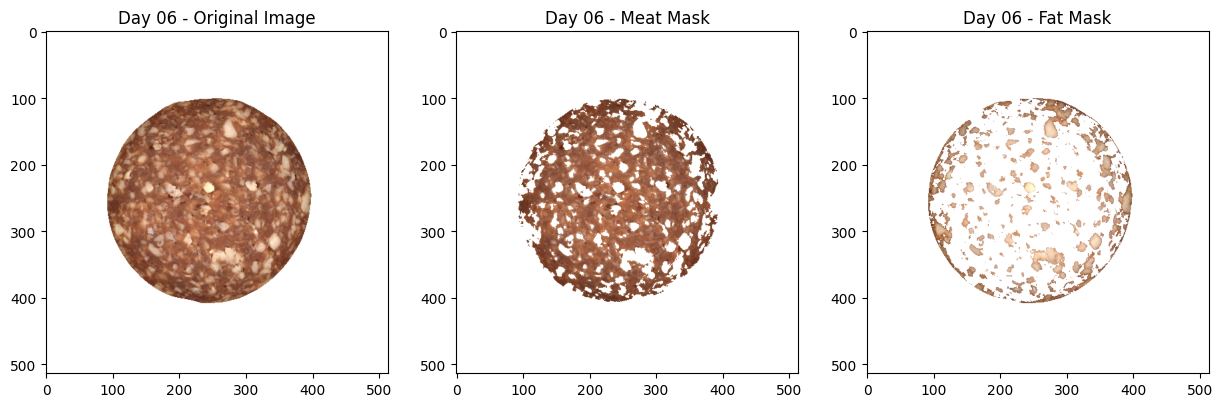

Day 06 - Fat Percentage: 25.99%
Day 06 - Multi Dimensional LSD Accuracy: 0.0019249278152069227 - Error Rate: 0.9980750721847931


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.023529412..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.023529412..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.15294118..255.0].


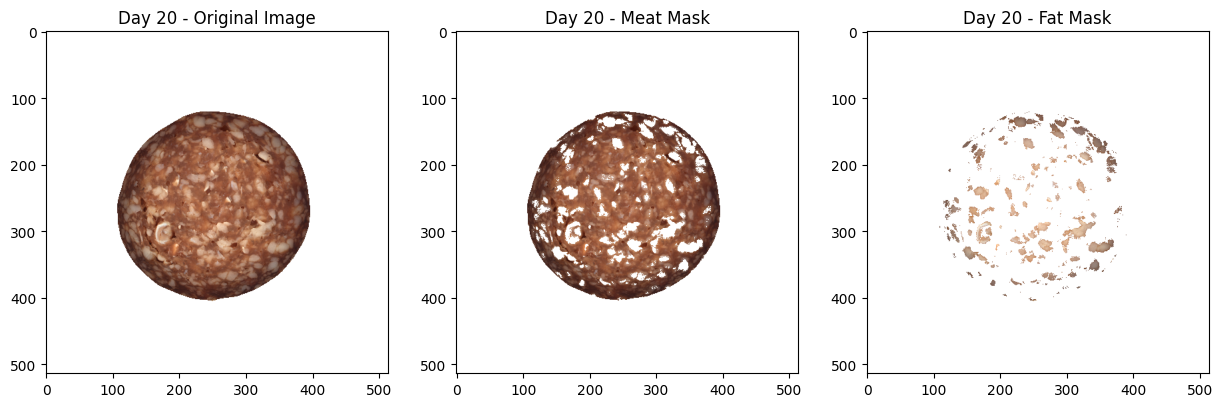

Day 20 - Fat Percentage: 14.78%
Day 20 - Multi Dimensional LSD Accuracy: 0.027058823529411802 - Error Rate: 0.9729411764705882


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.07450981..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.07450981..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1764706..255.0].


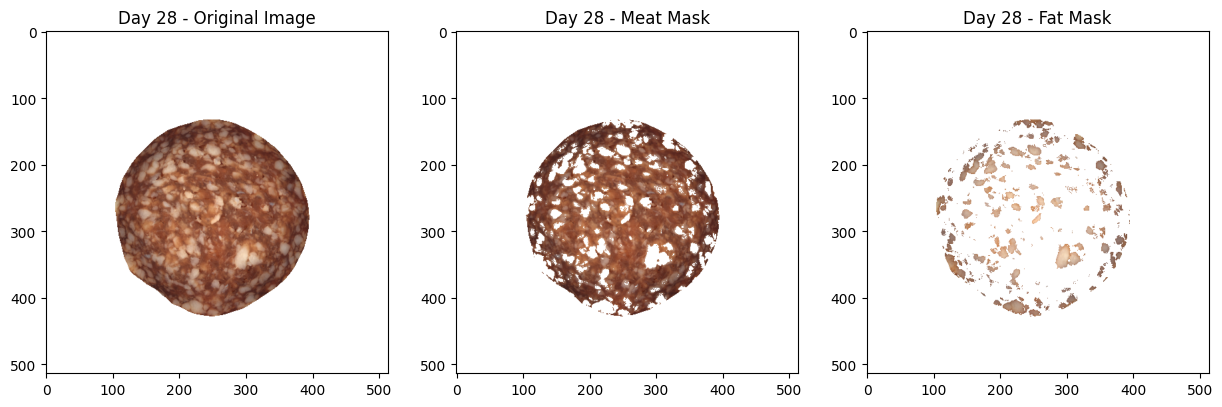

Day 28 - Fat Percentage: 18.95%
Day 28 - Multi Dimensional LSD Accuracy: 0.01833976833976836 - Error Rate: 0.9816602316602316


In [ ]:
from helper_functions.helpFunctions import setImagePix
### Load data for all days (again, yes)

best_train_day = "13"


days = ["01", "06", "13", "20", "28"]
days_data = {}
for day in days:
    multiIm, annotationIm = hf.loadMulti(
        f"multispectral_day{day}.mat", f"annotation_day{day}.png", dirIn
    )
    fat_annots = hf.getPix(multiIm, annotationIm[:, :, 1])
    meat_annots = hf.getPix(multiIm, annotationIm[:, :, 2])
    days_data[day] = {
        "multiIm": multiIm,
        "annotationIm": annotationIm,
        "fat_annots": fat_annots,
        "meat_annots": meat_annots,
        "color_im": plt.imread(f"./data/color_day{day}.png"),
    }
# fatPix1, fatR1, fatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 1])
# meatPix1, meatR1, meatC1 = hf.getPix(multiIm1, annotationIm1[:, :, 2])

### Create results table
# error_rates_table = np.zeros((len(days), len(days)))

data = days_data[best_train_day]

multiIm = data["multiIm"]
fatPix, fatR, fatC = data["fat_annots"]
meatPix, meatR, meatC = data["meat_annots"]

fat_mean = class_md_hat_mean(fatPix)
meat_mean = class_md_hat_mean(meatPix)

fat_mean_pooled_covar = pool_hat_covar(fatPix, meatPix)

prior_fat = 0.3
prior_meat = 1 - prior_fat

LSD_classifier_day = md_LSD_classifier(
    fat_mean,
    meat_mean,
    prior_fat,
    prior_meat,
    fat_mean_pooled_covar,
)
#### obtain error rate having evaluated on the remaining days
for day, data in days_data.items():
    if day == best_train_day:
        continue

    multiIm = data["multiIm"]
    fatPix, fatR, fatC = data["fat_annots"]
    meatPix, meatR, meatC = data["meat_annots"]
    salami_region = data["annotationIm"].max(axis=2).astype(bool)

    labeled_multiIm = np.zeros((multiIm.shape[0], multiIm.shape[1]))

    labeled_x, labeled_y = np.where(salami_region)

    for i, j in zip(labeled_x, labeled_y):
        labeled_multiIm[i, j] = (
            LSD_classifier_day(multiIm[i, j]) + 1
        )  # add one to differentiate from background

    fatPixId = np.stack((fatR, fatC), axis=1)
    meatPixId = np.stack((meatR, meatC), axis=1)

    er_md = error_rate(labeled_multiIm, fatPixId, meatPixId)

    masked_colour_image = setImagePix(data["color_im"], salami_region)

    ### meat mask
    meatOut = hf.setImagePix(data["color_im"], labeled_multiIm == 1)

    fatOut = hf.setImagePix(data["color_im"], labeled_multiIm == 2)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(masked_colour_image)
    plt.title(f"Day {day} - Original Image")
    plt.subplot(1, 3, 2)
    plt.imshow(meatOut)
    plt.title(f"Day {day} - Meat Mask")
    plt.subplot(1, 3, 3)
    plt.imshow(fatOut)
    plt.title(f"Day {day} - Fat Mask")
    plt.show()

    # print fat percentage
    fat_percentage = np.sum(labeled_multiIm == 2) / np.sum(salami_region)
    print(f"Day {day} - Fat Percentage: {fat_percentage:.2%}")
    print(
        f"Day {day} - Multi Dimensional LSD Accuracy: {1 - er_md} - Error Rate: {er_md}"
    )

#### Put that all into a table TxT

In [ ]:
# NOT MUCH